In [1]:
# 1. Setup and data
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import torch.nn as nn

SEED = 42
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
TASKS = ("image", "sentiment")
data_dir = Path("/kaggle/input/competitions/comp-472-project-fall-2026-concordia")
working_dir = Path("/kaggle/working")

labeled = {}
splits = {}
for task in TASKS:
    rows = pd.read_csv(data_dir / f"{task}_train.csv").sort_values("id")
    labeled[task] = rows
    splits[task] = train_test_split(
        rows, test_size=0.20, random_state=SEED, stratify=rows["label"]
    )
    train, val = splits[task]
    print(f"{task}: {len(train):,} train / {len(val):,} validation")
print(f"Training device: {device}")

image: 16,000 train / 4,000 validation
sentiment: 9,600 train / 2,400 validation
Training device: cuda:0


In [2]:
# 2. Networks
def make_model(task, input_size):
    if task == "image":
        # Project the 500 features into 16 learned maps of 16 by 16.
        return nn.Sequential(
            nn.BatchNorm1d(input_size),
            nn.Dropout(0.3),
            nn.Linear(input_size, 4096),
            nn.GELU(),
            nn.Unflatten(1, (16, 16, 16)),
            nn.Dropout2d(0.1),
            nn.Conv2d(16, 32, 3, padding=1),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.Dropout2d(0.2),
            nn.Conv2d(32, 32, 3, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.GELU(),
            nn.Flatten(),
            nn.Dropout(0.6),
            nn.Linear(32 * 8 * 8, 50),
        )

    # 768 features → hidden layers of 300 and 64 units → 3 classes
    return nn.Sequential(
        nn.Linear(input_size, 300),
        nn.ReLU(),
        nn.Linear(300, 64),
        nn.ReLU(),
        nn.Dropout(0.2),
        nn.Linear(64, 3),
    )

In [3]:
# 3. PyTorch training
def train_epoch(model, X, y, optimizer, loss_fn, batch_size, generator):
    model.train()
    total = torch.zeros((), device=device)
    correct = torch.zeros((), dtype=torch.long, device=device)

    order = torch.randperm(len(y), device=device, generator=generator)
    for idx in order.split(batch_size):
        xb, yb = X[idx], y[idx]
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()

        total += loss.detach() * len(xb)
        correct += (logits.detach().argmax(dim=1) == yb).sum()

    return total.item() / len(y), correct.item() / len(y)


def torch_predict(model, X):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(batch) for batch in X.split(256)])


def train_torch_model(task, train_df, val_df, *, epochs, schedule_epochs, batch_size):
    feature_cols = train_df.columns.drop(["id", "label"])
    X_tr = train_df[feature_cols].to_numpy(dtype="float32")
    X_va = val_df[feature_cols].to_numpy(dtype="float32")

    if task == "image":
        # Fit the scaler on training data only.
        scaler = StandardScaler().fit(X_tr)
        X_tr = scaler.transform(X_tr)
        X_va = scaler.transform(X_va)

    X_tr = torch.tensor(X_tr, dtype=torch.float32, device=device)
    X_va = torch.tensor(X_va, dtype=torch.float32, device=device)
    y_tr = torch.tensor(train_df["label"].to_numpy(), dtype=torch.long, device=device)
    y_va = None
    if "label" in val_df.columns:
        y_va = torch.tensor(val_df["label"].to_numpy(), dtype=torch.long, device=device)

    torch.manual_seed(SEED)
    model = make_model(task, len(feature_cols)).to(device)
    generator = torch.Generator(device=device).manual_seed(SEED)
    loss_fn = nn.CrossEntropyLoss()
    if task == "image":
        learning_rate, weight_decay = 0.0003, 0.05
    else:
        learning_rate, weight_decay = 0.001, 0.01
    optimizer = torch.optim.AdamW(
        model.parameters(), lr=learning_rate, weight_decay=weight_decay
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=schedule_epochs)
    history = {"epoch": [], "loss": [], "acc": [], "val_loss": [], "val_acc": []}

    if task == "image":
        # Score a fixed training sample with dropout off, like validation.
        sample_generator = torch.Generator().manual_seed(472)
        train_sample = torch.randperm(len(y_tr), generator=sample_generator)[:3200].to(device)

    with torch.backends.cudnn.flags(enabled=False):
        for epoch in range(1, epochs + 1):
            loss, acc = train_epoch(
                model, X_tr, y_tr, optimizer, loss_fn, batch_size, generator
            )
            scheduler.step()

            # Kaggle's test data has no labels.
            if y_va is not None:
                if task == "image":
                    train_logits = torch_predict(model, X_tr[train_sample])
                    loss = loss_fn(train_logits, y_tr[train_sample]).item()
                    acc = (train_logits.argmax(1) == y_tr[train_sample]).float().mean().item()
                logits = torch_predict(model, X_va)
                history["epoch"].append(epoch)
                history["loss"].append(loss)
                history["acc"].append(acc)
                history["val_loss"].append(loss_fn(logits, y_va).item())
                history["val_acc"].append(
                    (logits.argmax(dim=1) == y_va).float().mean().item()
                )
                if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
                    print(f"{task} epoch {epoch}: loss={loss:.3f}, "
                          f"validation accuracy={history['val_acc'][-1]:.2%}")

        preds = torch_predict(model, X_va).argmax(dim=1).cpu().numpy()

    return preds, pd.DataFrame(history)

In [4]:
# 4. Sentiment model
sentiment_params = dict(epochs=5, schedule_epochs=6, batch_size=64)
sentiment_train, sentiment_val = splits["sentiment"]
sentiment_pred, sentiment_hist = train_torch_model(
    "sentiment", sentiment_train, sentiment_val, **sentiment_params
)
sentiment_accuracy = (sentiment_pred == sentiment_val["label"].to_numpy()).mean()
print(f"Sentiment validation (300 / 64, epoch 5): {sentiment_accuracy:.2%}")

sentiment epoch 1: loss=0.849, validation accuracy=60.46%
sentiment epoch 5: loss=0.665, validation accuracy=66.54%
Sentiment validation (300 / 64, epoch 5): 66.54%


In [5]:
# 5. Image model
image_train, image_val = splits["image"]
# GELU and epoch 59 were selected on the inner development split.
image_params = dict(epochs=59, schedule_epochs=60, batch_size=128)
image_pred, image_hist = train_torch_model("image", image_train, image_val, **image_params)
image_accuracy = (image_pred == image_val["label"].to_numpy()).mean()
print(f"Image validation (GELU CNN, epoch 59): {image_accuracy:.2%}")

image epoch 1: loss=3.360, validation accuracy=17.60%
image epoch 10: loss=0.905, validation accuracy=38.93%
image epoch 20: loss=0.167, validation accuracy=42.10%
image epoch 30: loss=0.029, validation accuracy=44.35%
image epoch 40: loss=0.009, validation accuracy=45.53%
image epoch 50: loss=0.005, validation accuracy=46.08%
image epoch 59: loss=0.005, validation accuracy=46.30%
Image validation (GELU CNN, epoch 59): 46.30%


Mean image and sentiment validation accuracy: 56.42%


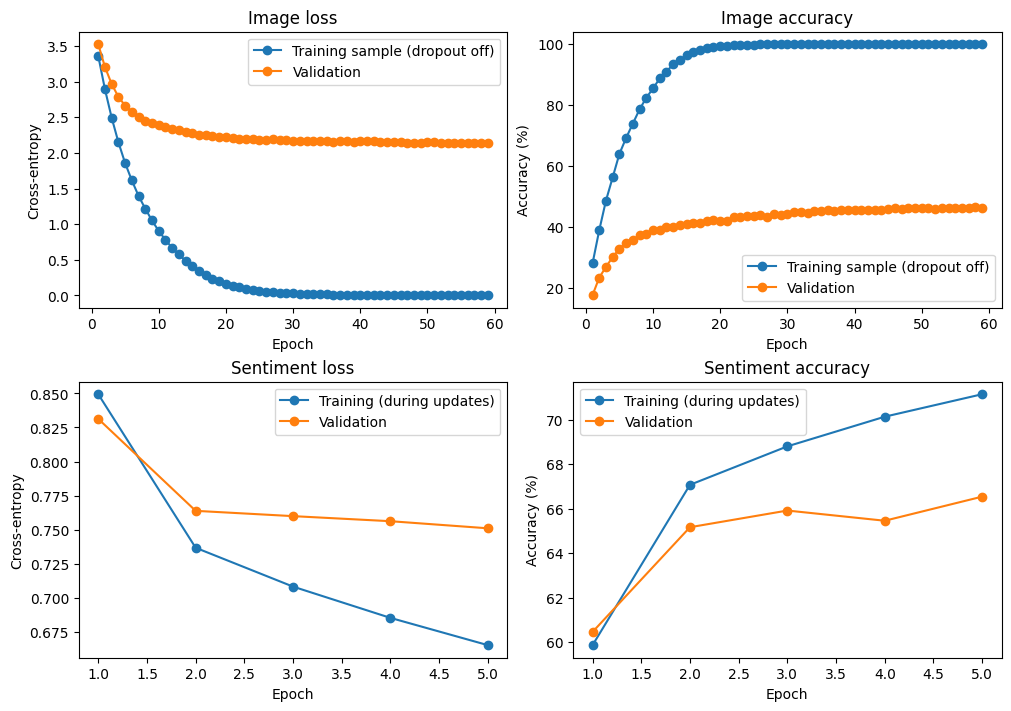

In [6]:
# 6. Results and learning curves
combined_accuracy = (image_accuracy + sentiment_accuracy) / 2
print(f"Mean image and sentiment validation accuracy: {combined_accuracy:.2%}")

fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
results = [("Image", image_hist), ("Sentiment", sentiment_hist)]

for (name, hist), (loss_ax, acc_ax) in zip(results, axes):
    epochs = hist["epoch"]
    train_label = "Training sample (dropout off)" if name == "Image" else "Training (during updates)"
    loss_ax.plot(epochs, hist["loss"], "o-", label=train_label)
    loss_ax.plot(epochs, hist["val_loss"], "o-", label="Validation")
    loss_ax.set(title=f"{name} loss", xlabel="Epoch", ylabel="Cross-entropy")
    loss_ax.legend()

    acc_ax.plot(epochs, 100 * hist["acc"], "o-", label=train_label)
    acc_ax.plot(epochs, 100 * hist["val_acc"], "o-", label="Validation")
    acc_ax.set(title=f"{name} accuracy", xlabel="Epoch", ylabel="Accuracy (%)")
    acc_ax.legend()

fig.savefig(working_dir / "cnn_learning_curves.png", dpi=160)
image_hist.to_csv(working_dir / "image_history.csv", index=False)
sentiment_hist.to_csv(working_dir / "sentiment_history.csv", index=False)
pd.DataFrame({
    "task": ["image", "sentiment"],
    "validation_accuracy": [image_accuracy, sentiment_accuracy],
}).to_csv(working_dir / "validation_scores.csv", index=False)
pd.DataFrame({
    "id": image_val["id"],
    "label": image_val["label"],
    "prediction": image_pred,
}).to_csv(working_dir / "image_validation_predictions.csv", index=False)
plt.show()

In [7]:
# 7. Kaggle prediction file
task_predictions = []
for task, params in (("image", image_params), ("sentiment", sentiment_params)):
    train_rows = labeled[task]
    test_rows = pd.read_csv(data_dir / f"{task}_test.csv")
    expected_columns = set(train_rows.columns) - {"label"}
    assert set(test_rows.columns) == expected_columns, f"Unexpected test columns for {task}"

    labels, _ = train_torch_model(task, train_rows, test_rows, **params)
    class_count = train_rows["label"].nunique()
    assert ((0 <= labels) & (labels < class_count)).all(), f"Invalid class for {task}"
    task_predictions.append(pd.DataFrame({"id": test_rows["id"], "label": labels}))

# Match sample file
sample = pd.read_csv(data_dir / "sample_submission.csv")
predictions = pd.concat(task_predictions, ignore_index=True)
assert list(sample.columns) == ["id", "label"] and len(sample) == 10_000
assert set(predictions["id"]) == set(sample["id"]), "Predictions do not match the expected test IDs"
submission = sample[["id"]].merge(predictions, on="id", how="left", validate="one_to_one")
assert submission["id"].equals(sample["id"]) and submission["label"].notna().all()

output = working_dir / "comp472_cnn_submission.csv"
submission.to_csv(output, index=False)
pd.testing.assert_frame_equal(pd.read_csv(output), submission)
print(f"Verified {len(submission):,} predictions in {output}")

Verified 10,000 predictions in /kaggle/working/comp472_cnn_submission.csv
